# Analise Estatistica de Risco de Credito

Este notebook foi estruturado para uma leitura inicial do dataset com foco em qualidade dos dados, estatisticas descritivas e sinais relevantes para um problema de classificacao de inadimplencia.

## Escopo da analise

1. Carregar o dataset com `pandas`.
2. Validar estrutura, tipos e dados faltantes.
3. Produzir estatisticas descritivas para variaveis numericas e categoricas.
4. Analisar a variavel alvo `loan_status`.
5. Investigar relacoes entre atributos, target e potenciais anomalias de qualidade.

In [1]:
from pathlib import Path
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

D:\dev\credit_risk_v2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carregamento do dataset

A estrategia abaixo prioriza o arquivo local em `data/credit_risk_dataset.csv`. Se ele nao existir, o notebook tenta baixar a base a partir do Kaggle via `kagglehub`.

In [2]:
ROOT_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
DATA_DIR = ROOT_DIR / "data"
LOCAL_DATA_PATH = DATA_DIR / "credit_risk_dataset.csv"
KAGGLE_DATASET = "laotse/credit-risk-dataset"


def load_credit_risk_dataset(local_path: Path = LOCAL_DATA_PATH) -> tuple[pd.DataFrame, Path]:
    if local_path.exists():
        dataset_path = local_path
    else:
        downloaded_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        csv_candidates = sorted(downloaded_dir.glob("*.csv"))
        if not csv_candidates:
            raise FileNotFoundError("Nenhum arquivo CSV foi encontrado no download do dataset.")
        dataset_path = csv_candidates[0]

    dataframe = pd.read_csv(dataset_path)
    return dataframe, dataset_path


df, dataset_path = load_credit_risk_dataset()

print(f"Dataset carregado de: {dataset_path}")
print(f"Dimensao: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

Dataset carregado de: D:\dev\credit_risk_v2\data\credit_risk_dataset.csv
Dimensao: 32,581 linhas x 12 colunas


## 2. Visao geral do dataset

Comecamos com uma leitura executiva da base: amostra dos dados, tipagem, cardinalidade e completude.

In [3]:
overview = pd.DataFrame(
    {
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "non_null": df.notna().sum().values,
        "nulls": df.isna().sum().values,
        "null_pct": (df.isna().mean() * 100).round(2).values,
        "unique_values": df.nunique(dropna=False).values,
    }
).sort_values(by=["null_pct", "unique_values"], ascending=[False, False])

display(df.head())
display(overview)
display(df.describe(include="all").T)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.00,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.00,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.00,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.00,MEDICAL,C,35000,14.27,1,0.55,Y,4


,column,dtype,non_null,nulls,null_pct,unique_values
7,loan_int_rate,float64,29465,3116,9.56,349
3,person_emp_length,float64,31686,895,2.75,37
1,person_income,int64,32581,0,0.00,4295
6,loan_amnt,int64,32581,0,0.00,753
9,loan_percent_income,float64,32581,0,0.00,77
0,person_age,int64,32581,0,0.00,58
11,cb_person_cred_hist_length,int64,32581,0,0.00,29
5,loan_grade,str,32581,0,0.00,7
4,loan_intent,str,32581,0,0.00,6
2,person_home_ownership,str,32581,0,0.00,4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_age,"32,581.00",NaN,NaN,NaN,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,"32,581.00",NaN,NaN,NaN,"66,074.85","61,983.12","4,000.00","38,500.00","55,000.00","79,200.00","6,000,000.00"
person_home_ownership,32581,4,RENT,16446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_emp_length,"31,686.00",NaN,NaN,NaN,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_intent,32581,6,EDUCATION,6453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_grade,32581,7,A,10777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,"32,581.00",NaN,NaN,NaN,"9,589.37","6,322.09",500.00,"5,000.00","8,000.00","12,200.00","35,000.00"
loan_int_rate,"29,465.00",NaN,NaN,NaN,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,"32,581.00",NaN,NaN,NaN,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,"32,581.00",NaN,NaN,NaN,0.17,0.11,0.00,0.09,0.15,0.23,0.83


## 3. Qualidade dos dados

Antes de qualquer modelagem, vale testar hipoteses basicas de qualidade. Para risco de credito, isso evita que outliers ou registros incoerentes contaminem conclusoes e features.

In [4]:
quality_checks = {
    "duplicated_rows": int(df.duplicated().sum()),
    "age_below_18": int((df["person_age"] < 18).sum()),
    "age_above_100": int((df["person_age"] > 100).sum()),
    "emp_length_negative": int((df["person_emp_length"] < 0).sum()),
    "emp_length_gt_age": int((df["person_emp_length"] > df["person_age"]).sum()),
    "loan_percent_income_gt_1": int((df["loan_percent_income"] > 1).sum()),
    "missing_interest_rate": int(df["loan_int_rate"].isna().sum()),
}

quality_summary = pd.Series(quality_checks, name="count").to_frame()
quality_summary["pct_dataset"] = (quality_summary["count"] / len(df) * 100).round(2)
display(quality_summary)

suspicious_mask = (
    (df["person_age"] > 100)
    | (df["person_emp_length"] < 0)
    | (df["person_emp_length"] > df["person_age"])
)

display(df.loc[suspicious_mask].head(10))

,count,pct_dataset
duplicated_rows,165,0.51
age_below_18,0,0.00
age_above_100,5,0.02
emp_length_negative,0,0.00
emp_length_gt_age,2,0.01
loan_percent_income_gt_1,0,0.00
missing_interest_rate,3116,9.56


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
81,144,250000,RENT,4.00,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.00,EDUCATION,B,6000,11.86,0,0.03,N,2
210,21,192000,MORTGAGE,123.00,VENTURE,A,20000,6.54,0,0.10,N,4
575,123,80004,RENT,2.00,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.00,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.00,PERSONAL,C,5000,12.73,0,0.00,N,25


## 4. Estatisticas descritivas das variaveis numericas

A tabela abaixo resume tendencia central, dispersao e assimetria. Em um workflow senior, esse bloco ajuda a separar rapidamente sinais robustos de distribuicoes possivelmente distorcidas.

In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

numeric_summary = df[numeric_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
quantiles = df[numeric_cols].quantile([0.25, 0.50, 0.75, 0.95]).T
quantiles.columns = ["q25", "q50", "q75", "q95"]

numeric_summary = numeric_summary.join(quantiles)
numeric_summary["skew"] = df[numeric_cols].skew().round(2)

display(numeric_summary.round(2).sort_values(by="std", ascending=False))

,count,mean,median,std,min,max,q25,q50,q75,q95,skew
person_income,"32,581.00","66,074.85","55,000.00","61,983.12","4,000.00","6,000,000.00","38,500.00","55,000.00","79,200.00","138,000.00",32.87
loan_amnt,"32,581.00","9,589.37","8,000.00","6,322.09",500.00,"35,000.00","5,000.00","8,000.00","12,200.00","24,000.00",1.19
person_age,"32,581.00",27.73,26.00,6.35,20.00,144.00,23.00,26.00,30.00,40.00,2.58
person_emp_length,"31,686.00",4.79,4.00,4.14,0.00,123.00,2.00,4.00,7.00,13.00,2.61
cb_person_cred_hist_length,"32,581.00",5.80,4.00,4.06,2.00,30.00,3.00,4.00,8.00,14.00,1.66
loan_int_rate,"29,465.00",11.01,10.99,3.24,5.42,23.22,7.90,10.99,13.47,16.32,0.21
loan_status,"32,581.00",0.22,0.00,0.41,0.00,1.00,0.00,0.00,0.00,1.00,1.36
loan_percent_income,"32,581.00",0.17,0.15,0.11,0.00,0.83,0.09,0.15,0.23,0.38,1.06


## 5. Analise da variavel alvo

Aqui avaliamos o balanceamento de `loan_status`, ponto central para entender se o problema exigira estrategias como reamostragem, pesos de classe ou metricas alem de acuracia.

,count,pct
loan_status,,
0,25473,78.18
1,7108,21.82


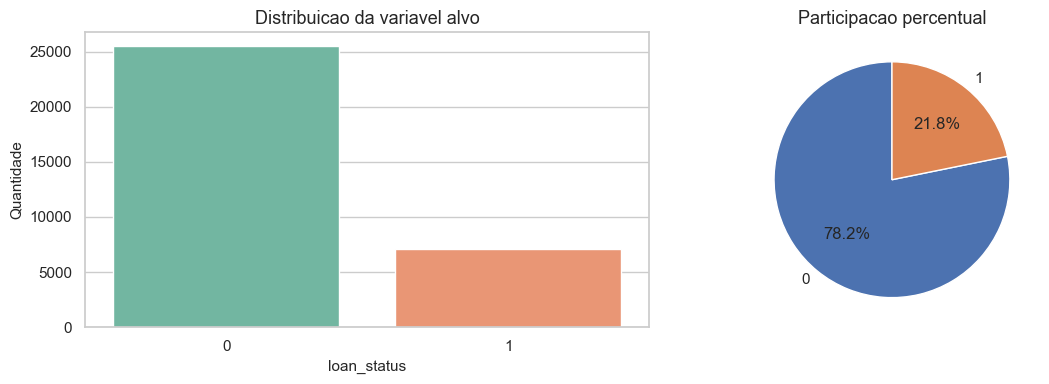

In [6]:
target_distribution = df["loan_status"].value_counts().rename_axis("loan_status").to_frame("count")
target_distribution["pct"] = (target_distribution["count"] / len(df) * 100).round(2)
display(target_distribution)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="loan_status", hue="loan_status", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Distribuicao da variavel alvo")
axes[0].set_xlabel("loan_status")
axes[0].set_ylabel("Quantidade")

axes[1].pie(target_distribution["count"], labels=target_distribution.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Participacao percentual")

plt.tight_layout()
plt.show()

## 6. Variaveis categoricas e taxa de inadimplencia

Em datasets de credito, variaveis categoricas normalmente carregam sinal relevante. O objetivo aqui e observar volume por categoria e sua respectiva taxa media de default.

### person_home_ownership

,records,share_pct,default_rate_pct
person_home_ownership,,,
RENT,16446,50.48,31.57
MORTGAGE,13444,41.26,12.57
OWN,2584,7.93,7.47
OTHER,107,0.33,30.84


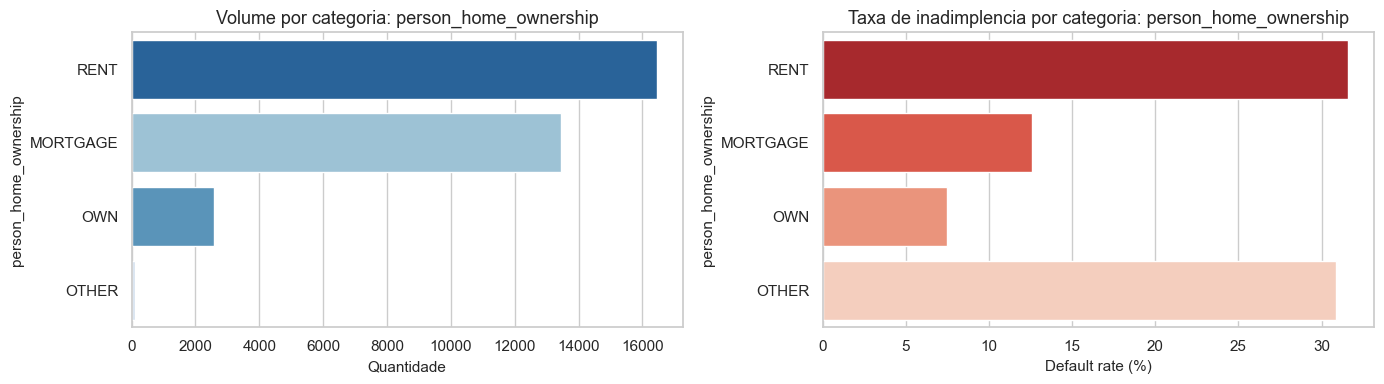

### loan_intent

,records,share_pct,default_rate_pct
loan_intent,,,
EDUCATION,6453,19.81,17.22
MEDICAL,6071,18.63,26.70
VENTURE,5719,17.55,14.81
PERSONAL,5521,16.95,19.89
DEBTCONSOLIDATION,5212,16.00,28.59
HOMEIMPROVEMENT,3605,11.06,26.10


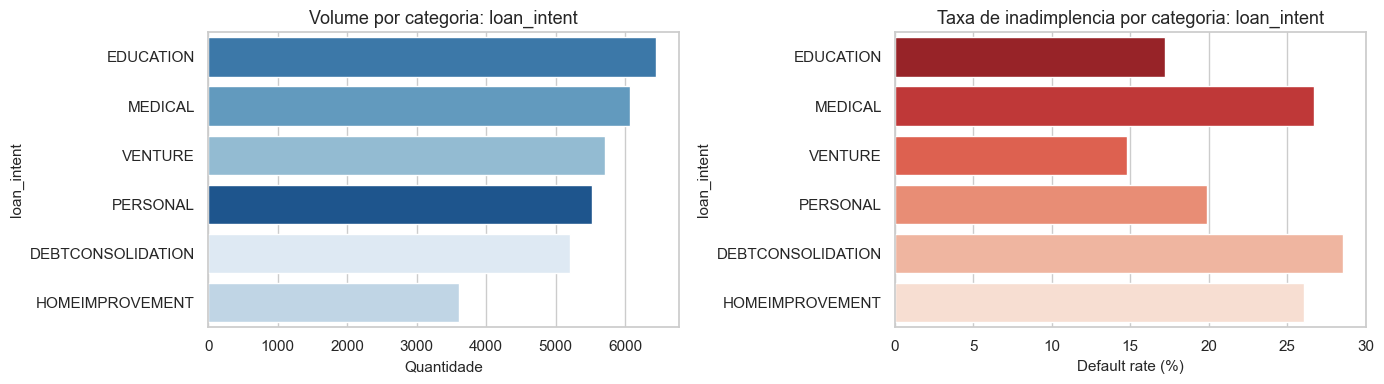

### loan_grade

,records,share_pct,default_rate_pct
loan_grade,,,
A,10777,33.08,9.96
B,10451,32.08,16.28
C,6458,19.82,20.73
D,3626,11.13,59.05
E,964,2.96,64.42
F,241,0.74,70.54
G,64,0.20,98.44


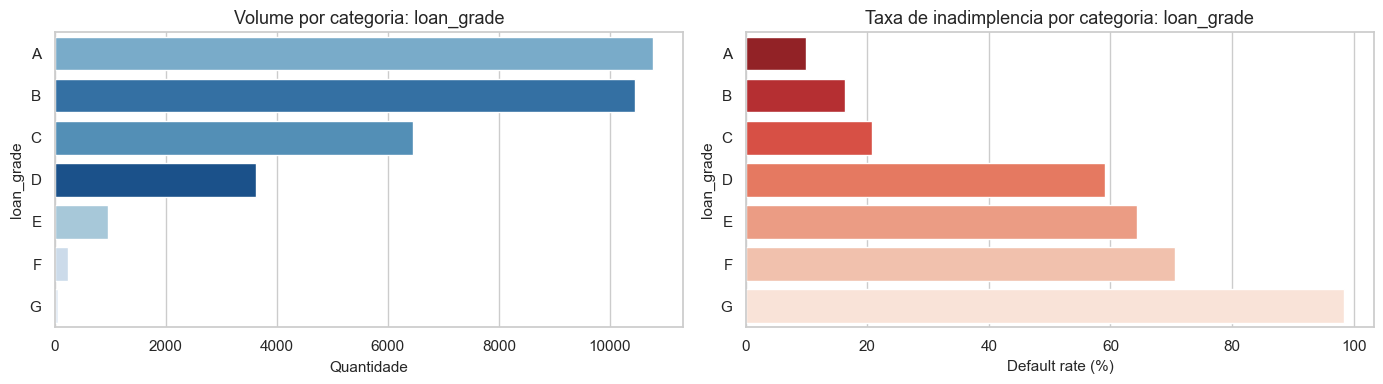

### cb_person_default_on_file

,records,share_pct,default_rate_pct
cb_person_default_on_file,,,
N,26836,82.37,18.39
Y,5745,17.63,37.81


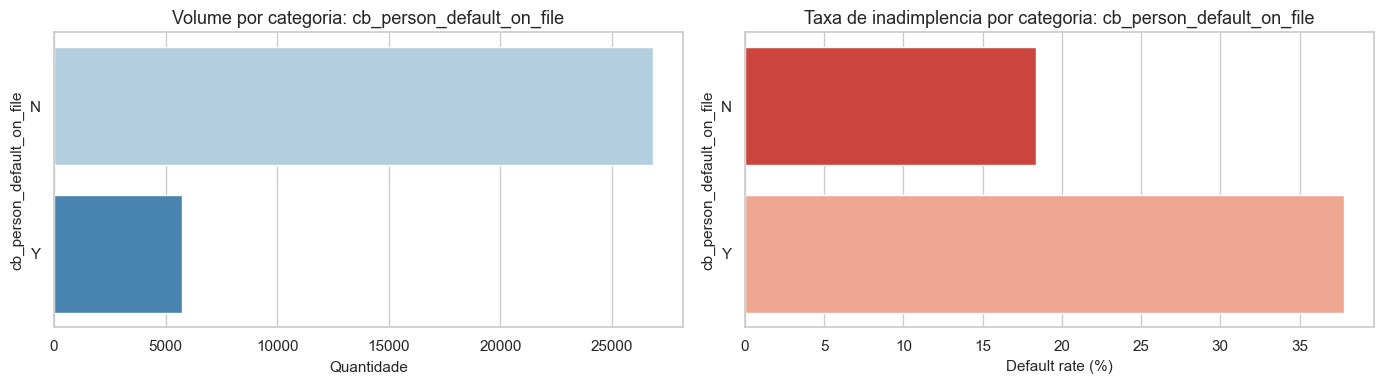

In [7]:
categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

for column in categorical_cols:
    category_summary = (
        df.groupby(column)
        .agg(records=("loan_status", "size"), default_rate=("loan_status", "mean"))
        .sort_values(by="records", ascending=False)
    )
    category_summary["share_pct"] = (category_summary["records"] / len(df) * 100).round(2)
    category_summary["default_rate_pct"] = (category_summary["default_rate"] * 100).round(2)

    display(Markdown(f"### {column}"))
    display(category_summary[["records", "share_pct", "default_rate_pct"]])

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.countplot(data=df, y=column, order=category_summary.index, hue=column, legend=False, palette="Blues_r", ax=axes[0])
    axes[0].set_title(f"Volume por categoria: {column}")
    axes[0].set_xlabel("Quantidade")
    axes[0].set_ylabel(column)

    sns.barplot(
        x=category_summary["default_rate_pct"],
        y=category_summary.index,
        palette="Reds_r",
        ax=axes[1],
    )
    axes[1].set_title(f"Taxa de inadimplencia por categoria: {column}")
    axes[1].set_xlabel("Default rate (%)")
    axes[1].set_ylabel(column)

    plt.tight_layout()
    plt.show()

## 7. Variaveis numericas versus inadimplencia

Esse corte ajuda a entender quais variaveis parecem separar melhor bons e maus pagadores ja na analise exploratoria.

person_income           loan_amnt          loan_int_rate         \
                     mean    median      mean   median          mean median   
loan_status                                                                   
0               70,804.36 60,000.00  9,237.46 8,000.00         10.44  10.59   
1               49,125.65 41,498.00 10,850.50 9,600.00         13.06  13.49   

            loan_percent_income        cb_person_cred_hist_length         
                           mean median                       mean median  
loan_status                                                               
0                          0.15   0.13                       5.84   4.00  
1                          0.25   0.24                       5.69   4.00

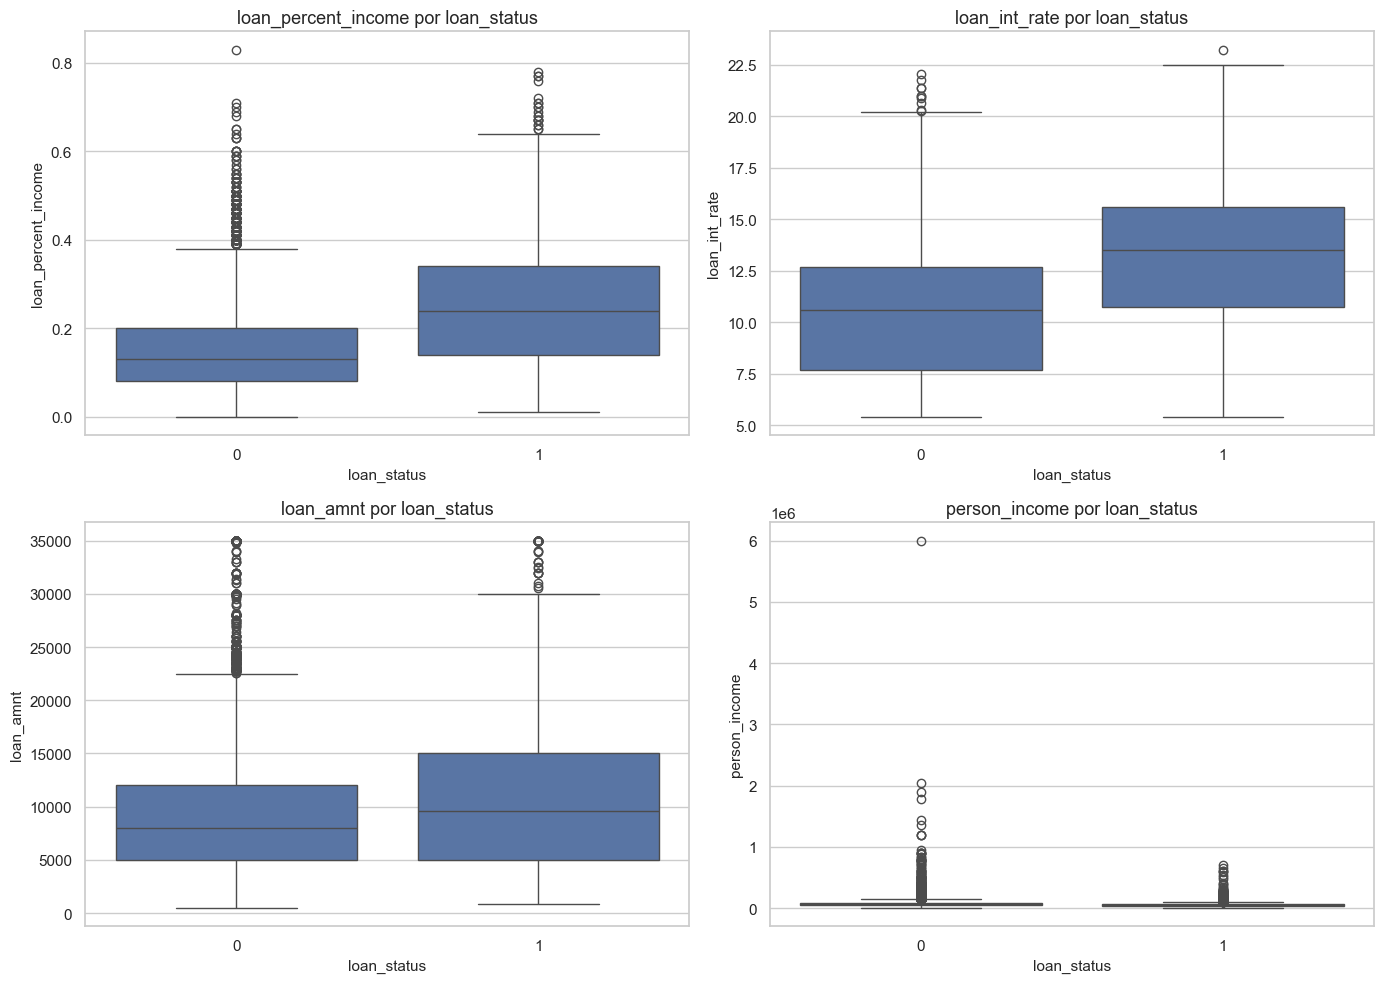

In [8]:
key_numeric_features = [
    "person_income",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

target_numeric_summary = df.groupby("loan_status")[key_numeric_features].agg(["mean", "median"]).round(2)
display(target_numeric_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="loan_status", y="loan_percent_income", ax=axes[0, 0])
axes[0, 0].set_title("loan_percent_income por loan_status")

sns.boxplot(data=df, x="loan_status", y="loan_int_rate", ax=axes[0, 1])
axes[0, 1].set_title("loan_int_rate por loan_status")

sns.boxplot(data=df, x="loan_status", y="loan_amnt", ax=axes[1, 0])
axes[1, 0].set_title("loan_amnt por loan_status")

sns.boxplot(data=df, x="loan_status", y="person_income", ax=axes[1, 1])
axes[1, 1].set_title("person_income por loan_status")

plt.tight_layout()
plt.show()

## 8. Correlacao entre variaveis numericas

Correlacao nao substitui modelagem, mas ajuda a identificar rapidamente colinearidade e variaveis com relacao linear mais forte com o target.

,loan_status
loan_status,1.00
loan_percent_income,0.38
loan_int_rate,0.34
loan_amnt,0.10
cb_person_cred_hist_length,-0.02
person_age,-0.02
person_emp_length,-0.08
person_income,-0.14


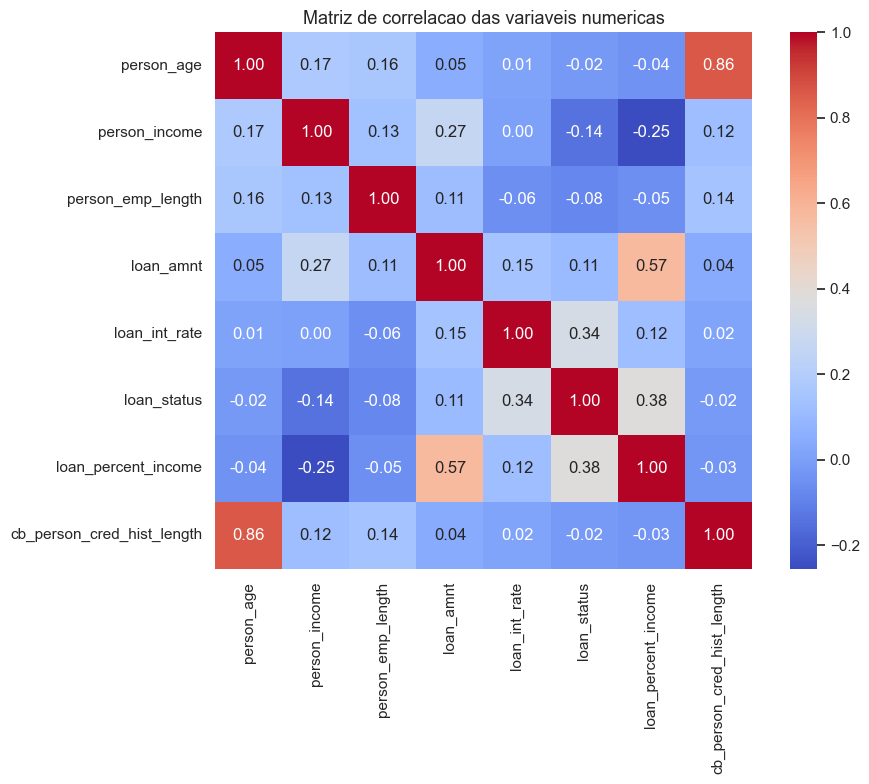

In [9]:
correlation_matrix = df[numeric_cols].corr()
display(correlation_matrix[['loan_status']].sort_values(by='loan_status', ascending=False).round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Matriz de correlacao das variaveis numericas")
plt.tight_layout()
plt.show()

## 9. Principais insights executivos

Fechamos a exploracao com um resumo orientado a negocio e modelagem.

In [10]:
default_rate = df["loan_status"].mean() * 100
top_linear_drivers = (
    correlation_matrix["loan_status"]
    .drop("loan_status")
    .abs()
    .sort_values(ascending=False)
    .head(3)
)

insights = [
    f"- A taxa media de inadimplencia observada na base e de {default_rate:.2f}%.",
    f"- Foram identificados {quality_checks['emp_length_gt_age']} registros com `person_emp_length` maior que `person_age`, o que sugere necessidade de saneamento antes da modelagem.",
    "- Variaveis categoricas como `loan_grade`, `loan_intent` e `cb_person_default_on_file` devem ser tratadas com bastante atencao, pois tendem a carregar forte sinal de risco.",
    f"- As tres variaveis numericas com maior relacao linear absoluta com `loan_status` nesta leitura inicial foram: {', '.join(top_linear_drivers.index.tolist())}.",
    "- Antes do treino, vale considerar tratamento de outliers, encoding de categoricas, imputacao de faltantes e validacao estratificada.",
]

display(Markdown("\n".join(insights)))

- A taxa media de inadimplencia observada na base e de 21.82%.
- Foram identificados 2 registros com `person_emp_length` maior que `person_age`, o que sugere necessidade de saneamento antes da modelagem.
- Variaveis categoricas como `loan_grade`, `loan_intent` e `cb_person_default_on_file` devem ser tratadas com bastante atencao, pois tendem a carregar forte sinal de risco.
- As tres variaveis numericas com maior relacao linear absoluta com `loan_status` nesta leitura inicial foram: loan_percent_income, loan_int_rate, person_income.
- Antes do treino, vale considerar tratamento de outliers, encoding de categoricas, imputacao de faltantes e validacao estratificada.